# QuantumSAR — SAR image segmentation with QAOA

This notebook walks through the full method behind the QuantumSAR app:

1. synthetic MSTAR-like SAR data with Gamma speckle,
2. the Markov-random-field (MRF) energy from the Thales use case,
3. its exact rewrite as a QUBO / Ising Hamiltonian,
4. QAOA on one tile (local statevector + the Classiq circuit),
5. tile decomposition for the full 64×64 image,
6. comparison with classical solvers, 3-class and edge detection, and honest limitations.

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "../src")
from quantumsar.data import load_sample, to_uint8, SampleSpec, make_sample
from quantumsar.pipeline import SegParams, fit_model, segment
from quantumsar import mrf
cmap = plt.matplotlib.colors.ListedColormap(["#283042", "#ffa600", "#4084ff"])

## 1. Data
SAR intensity = reflectivity × speckle, with speckle ~ Gamma(L, 1/L) (L = number of looks).
Targets are bright, their radar shadow is dark. The set includes **no-target** and **low-SNR** images.

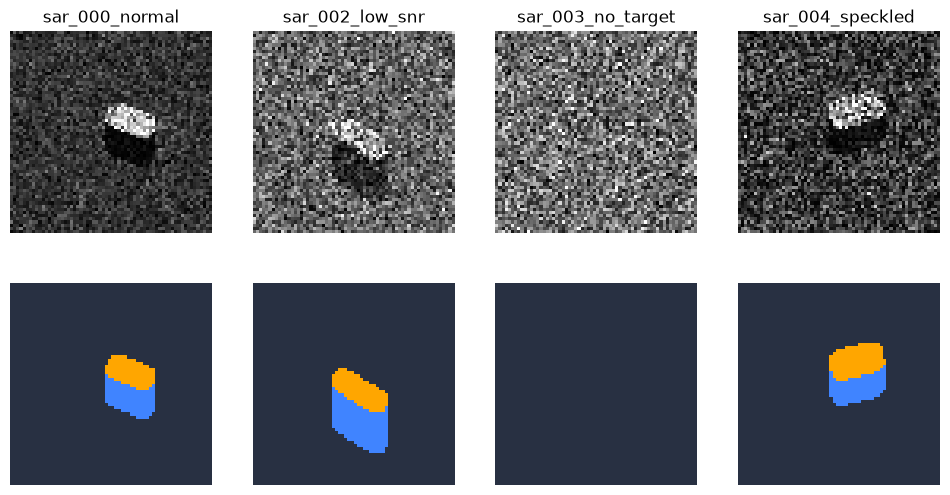

In [2]:
names = ["sar_000_normal", "sar_002_low_snr", "sar_003_no_target", "sar_004_speckled"]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for j, n in enumerate(names):
    img, gt = load_sample("../data", n)
    ax[0, j].imshow(to_uint8(img), cmap="gray"); ax[0, j].set_title(n)
    ax[1, j].imshow(gt, cmap=cmap, vmin=0, vmax=2)
for a in ax.ravel(): a.axis("off")

## 2. MRF energy
$$E(x)=\sum_i \theta_i(x_i) + \lambda\sum_{(i,j)\in\mathcal E}[x_i\neq x_j],\qquad
\theta_i(k) = L\Big(\frac{z_i}{\mu_k}+\log\mu_k\Big)$$
The unary term is the Gamma negative log-likelihood; class means $\mu_k$ and the number of looks $L$ are
estimated without supervision (robust clutter statistics + one ICM-EM step).

In [3]:
img, gt = load_sample("../data", "sar_002_low_snr")
prm = SegParams(n_classes=2)
model = fit_model(img, prm)
print("estimated looks L =", round(model.looks, 2), " class means =", model.means.round(3))
ml = np.argmin(model.unary, axis=2)
print("pixel-wise ML energy:", round(mrf.energy(model, ml), 1))

estimated looks L = 3.97  class means = [0.928 1.818]
pixel-wise ML energy: 4153.5


## 3. QUBO / Ising encoding of a tile
Binary: $x_i\in\{0,1\}$, $\theta_i(x)=\theta_{i0}+(\theta_{i1}-\theta_{i0})x_i$ and $[x_i\ne x_j]=x_i+x_j-2x_ix_j$.
Pixels just outside the tile are fixed and act as **external fields**. With $x=(1-s)/2$ this is an Ising model
$H=\sum_i h_iZ_i+\sum_{ij}J_{ij}Z_iZ_j$. 3-class uses one-hot bits with penalty $P(\sum_k y_{ik}-1)^2$.

We check the encoding against brute force on a 3×3 tile:

In [4]:
from quantumsar.qubo import tile_qubo, brute_force, tile_energy_from_model
import itertools
q = tile_qubo(model, ml, 26, 30, 3, 3)
b, e = brute_force(q)
best = min(tile_energy_from_model(model, ml, q, np.array(t)) for t in itertools.product((0, 1), repeat=9))
print(f"{q.n} qubits | QUBO optimum {e:.4f} | brute force over labelings {best:.4f}")
h, J, off = q.to_ising(); print("Ising: |h| terms", len(h), " ZZ couplings", len(J))

9 qubits | QUBO optimum 10.5000 | brute force over labelings 10.5000
Ising: |h| terms 9  ZZ couplings 12


## 4. QAOA on one tile
$|\psi(\gamma,\beta)\rangle=\prod_k e^{-i\beta_k\sum X}e^{-i\gamma_k H_C}|+\rangle^{\otimes n}$.
On Classiq the cost layer is `RZ(2γh_i)` + `CX·RZ(2γJ_ij)·CX`, the mixer `RX(2β)`; all coefficients are
**execution parameters**, so one synthesized program serves every tile of the same shape and a whole
checkerboard colour is sampled in one batched job. Angles are optimised (COBYLA) on an exact statevector.

In [5]:
from quantumsar.solvers.tile_solvers import StatevectorQAOA
sim = StatevectorQAOA(q)
for p in (1, 2, 3):
    params, val, nfev = sim.optimise(p, maxiter=80)
    pr = np.abs(sim.state(params))**2
    print(f"p={p}: P(optimum) = {pr[np.argmin(sim.energies)]:.3f}  vs random 1/2^n = {1/2**q.n:.4f}")

p=1: P(optimum) = 0.134  vs random 1/2^n = 0.0020


p=2: P(optimum) = 0.393  vs random 1/2^n = 0.0020


p=3: P(optimum) = 0.438  vs random 1/2^n = 0.0020


In [6]:
# The Qmod model that runs on Classiq (model creation works offline; synthesis needs credentials)
import inspect
from quantumsar.solvers.classiq_qaoa import build_qaoa_model
print(inspect.getsource(build_qaoa_model))
import classiq
m = classiq.create_model(build_qaoa_model(9, sorted(q.to_ising()[1].keys()), 2))
print("serialized Qmod model:", len(m), "chars")

def build_qaoa_model(n: int, edges: list[tuple[int, int]], p: int):
    """Return the Qmod ``main`` for an n-qubit QAOA with parametric coefficients."""
    from classiq import CArray, CReal, CX, Output, QArray, QBit, RX, RZ, allocate, hadamard_transform, qfunc

    n_params = 2 * p + n + len(edges)

    @qfunc
    def main(params: CArray[CReal, n_params], v: Output[QArray[QBit, n]]):  # noqa: F821
        allocate(v)
        hadamard_transform(v)
        for k in range(p):
            g = params[k]
            for i in range(n):
                RZ(2 * g * params[2 * p + i], v[i])
            for e, (i, j) in enumerate(edges):
                CX(v[i], v[j])
                RZ(2 * g * params[2 * p + n + e], v[j])
                CX(v[i], v[j])
            for i in range(n):
                RX(2 * params[p + k], v[i])

    return main



serialized Qmod model: 151517 chars


In [7]:
# Circuit metrics measured when the 3x3 tile circuit was synthesized on Classiq (from the cache)
from quantumsar.pipeline import load_cached_quantum
cached = load_cached_quantum(*load_sample("../data", "sar_000_normal")[:1], SegParams(solver="classiq"))
print(cached[1]["tiling"].get("circuit") if cached else "no cached Classiq run")

{'width': 9, 'depth': 41, 'qubits_logical': 9, 'edges': 12, 'p': 2, 'synthesis_seconds': 9.49}


## 5. Tiling the full image
Checkerboard block-coordinate descent: tiles of one colour share no edge → solved as one batch; a tile is
accepted only if it lowers the energy (monotone); a coarse 4×-downsampled pass decides large structures;
grid offsets alternate between sweeps; ICM sweeps stitch seams.

{'tiles_total': 1040, 'tiles_solved': 175, 'tiles_improved': 21, 'max_qubits': 9, 'qaoa_mean_p_opt': 0.3899092089185299, 'qaoa_mean_p_opt_uniform': 0.030848214285714284, 'qaoa_found_opt_rate': 1.0}


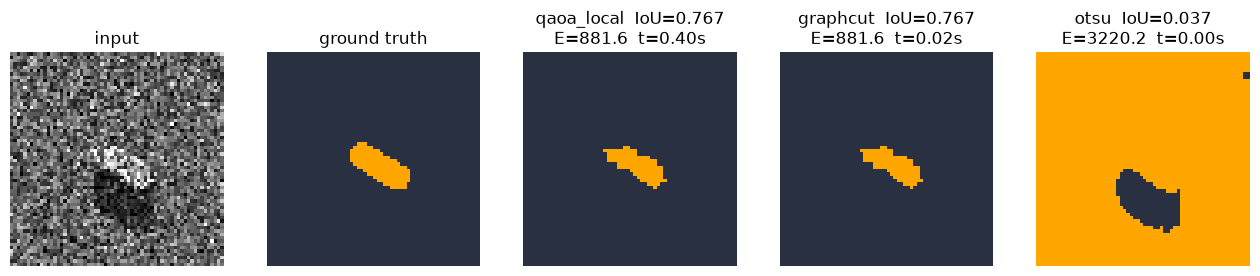

In [8]:
res = {s: segment(img, SegParams(solver=s), gt) for s in ["qaoa_local", "graphcut", "otsu"]}
fig, ax = plt.subplots(1, 5, figsize=(16, 3.5))
ax[0].imshow(to_uint8(img), cmap="gray"); ax[0].set_title("input")
ax[1].imshow(gt == 1, cmap=cmap, vmin=0, vmax=2); ax[1].set_title("ground truth")
for a, (s, r) in zip(ax[2:], res.items()):
    a.imshow(r["labels"], cmap=cmap, vmin=0, vmax=2)
    a.set_title(f"{s}  IoU={r['metrics']['iou']:.3f}\nE={r['energy']:.1f}  t={r['runtime_s']:.2f}s")
for a in ax: a.axis("off")
print({k: v for k, v in res["qaoa_local"]["info"].items() if k.startswith(("tiles", "qaoa", "max"))})

## 6. Three classes and edge detection

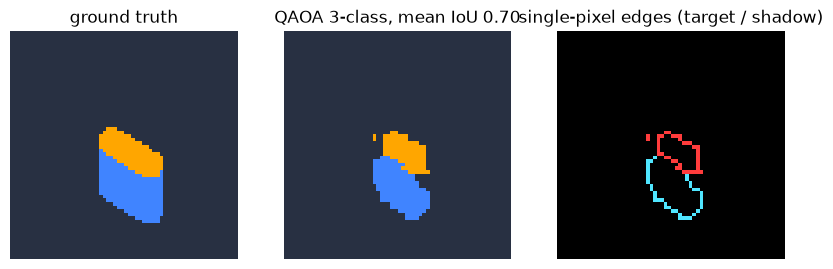

In [9]:
r3 = segment(img, SegParams(solver="qaoa_local", n_classes=3), gt, edges=True)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
ax[0].imshow(gt, cmap=cmap, vmin=0, vmax=2); ax[0].set_title("ground truth")
ax[1].imshow(r3["labels"], cmap=cmap, vmin=0, vmax=2); ax[1].set_title(f"QAOA 3-class, mean IoU {r3['metrics']['iou']:.2f}")
ax[2].imshow(r3["edge_classes"], cmap=plt.matplotlib.colors.ListedColormap(["k", "#ff3c3c", "#50e6ff"]), vmin=0, vmax=2)
ax[2].set_title("single-pixel edges (target / shadow)")
for a in ax: a.axis("off")

## 7. Results and honest limitations
See `results/RESULTS.md` for the 50-image benchmark. Key points:

* On 2-class images tiled QAOA reaches within ~0.1 % of the exact graph-cut energy, but **graph cut is exact and
  far faster classically** for this submodular binary problem — the quantum approach is a proof of concept,
  not a speed-up.
* Tiles are tiny (9 qubits binary, 12 qubits for 3-class one-hot) because of simulator limits; the quantum
  solver optimises local blocks, global optimality is not guaranteed.
* QAOA angles are pre-trained on a classical statevector and transferred between tiles.
* Live Classiq runs take ~2–4 min per image (cloud round-trips), so the public app serves cached Classiq runs.